# BigMart Sales Prediction - Complete End-to-End Pipeline
## Exploratory Data Analysis, Data Cleaning, Outlier Treatment, Feature Engineering, and Predictive Modeling

This notebook provides a complete, self-contained solution for the BigMart Sales Prediction competition.
It is written in clean, step-by-step, easy-to-understand code.

### Table of Contents:
---
### PART 1: DATA CLEANING & EXPLORATORY DATA ANALYSIS (EDA)
1. **Step 1**: Load Dataset and Inspect Dimensions
2. **Step 2**: Clean Inconsistent Categories (`Item_Fat_Content`)
3. **Step 3**: Fix Impossible 0 Values (`Item_Visibility = 0`)
4. **Step 4**: Find and Fix Missing Values (`Item_Weight` & `Outlet_Size`)
5. **Step 5**: Check for Duplicate Rows
6. **Step 6**: Continuous Features Distributions (Histograms & KDE)
7. **Step 7**: Categorical Variables Countplots
8. **Step 8**: Outlier Detection (Boxplots, IQR, 3-Sigma Rule, Percentiles p01, p98, p99)
9. **Step 9**: Outlier Treatment (Outlier Flag, 99th Percentile Capping, Log Transformation)
10. **Step 10**: Bivariate Analysis & Correlation Heatmap
11. **Step 11**: Export Clean Data (`cleaned_train.csv`)

---
### PART 2: FEATURE ENGINEERING, MODELING & PREDICTIONS
12. **Step 12**: Load and Preprocess Test Dataset (`test.csv`)
13. **Step 13**: Feature Engineering (`Outlet_Age`, `Item_Category`, `Price_Per_Weight`)
14. **Step 14**: One-Hot Encoding (`pd.get_dummies(..., drop_first=True)`)
15. **Step 15**: Prepare Feature Matrix (X) and Target (y)
16. **Step 16**: Train-Validation Split and Feature Scaling (`StandardScaler`)
17. **Step 17**: Train & Compare 4 Regression Models (Linear, Ridge, Lasso, Random Forest)
18. **Step 18**: Visualizing Model Performance, Predictions & Residuals
19. **Step 19**: Key Sales Drivers & Business Interpretation (Coefficients & Importances)
20. **Step 20**: Generate Final Test Predictions (`submission.csv`)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual settings
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)


## Step 1: Load the Dataset and Inspect Dimensions
We load `train.csv` and view its rows, columns, and first few records.


In [2]:
# Load dataset
df = pd.read_csv('train.csv')

# Dataset shape
rows, cols = df.shape
print(f"Dataset Shape: {rows} Rows, {cols} Columns\n")

# View first 5 rows
df.head()


Dataset Shape: 8523 Rows, 12 Columns



,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [3]:
# Summary information of columns and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [4]:
# Descriptive statistics for numeric features
df.describe()


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


## Step 2: Clean Inconsistent Categories in Item_Fat_Content
In `Item_Fat_Content`, 'LF', 'low fat', and 'Low Fat' are the same. Also 'reg' and 'Regular' are the same.
Let us standardize them to just 'Low Fat' and 'Regular'.


In [5]:
# Value counts before cleaning
print("Before cleaning:")
print(df['Item_Fat_Content'].value_counts())


Before cleaning:
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


In [6]:
# Replace abbreviations and inconsistent text
df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

# Value counts after cleaning
print("After cleaning:")
print(df['Item_Fat_Content'].value_counts())


After cleaning:
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


## Step 3: Fix Impossible 0 Values in Item_Visibility
A product displayed in a store cannot take up 0% display space. These zeros are missing measurements that we replace with the product's average visibility.


In [7]:
# Count how many products have 0 visibility
zero_vis = (df['Item_Visibility'] == 0).sum()
print(f"Number of rows with Item_Visibility = 0: {zero_vis}")


Number of rows with Item_Visibility = 0: 526


In [8]:
# Replace 0 with NaN
df['Item_Visibility'] = df['Item_Visibility'].replace(0, np.nan)

# Impute with average visibility for each product across all stores
vis_mean = df.groupby('Item_Identifier')['Item_Visibility'].transform('mean')
df['Item_Visibility'] = df['Item_Visibility'].fillna(vis_mean)

# Fallback: fill any remaining with median
df['Item_Visibility'] = df['Item_Visibility'].fillna(df['Item_Visibility'].median())

print("Remaining zeros in Item_Visibility:", (df['Item_Visibility'] == 0).sum())
print("Remaining NaNs in Item_Visibility:", df['Item_Visibility'].isnull().sum())


Remaining zeros in Item_Visibility: 0
Remaining NaNs in Item_Visibility: 0


## Step 4: Find and Fix Missing Values
Check which columns have missing values.


In [9]:
# Check missing value counts
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0])


Missing values per column:
Item_Weight    1463
Outlet_Size    2410
dtype: int64


### 4.1 Fix Missing Item_Weight
Each product has an `Item_Identifier`. We impute each missing weight with the mean weight of that item across other stores.


In [10]:
# Mean weight per product
item_weight_mean = df.groupby('Item_Identifier')['Item_Weight'].transform('mean')
df['Item_Weight'] = df['Item_Weight'].fillna(item_weight_mean)

# Fallback with overall median weight
df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Weight'].median())

print("Missing Item_Weight remaining:", df['Item_Weight'].isnull().sum())


Missing Item_Weight remaining: 0


### 4.2 Fix Missing Outlet_Size
Check which store types have missing `Outlet_Size`.


In [11]:
# Crosstab between Outlet_Type and Outlet_Size
print(pd.crosstab(df['Outlet_Type'], df['Outlet_Size'].fillna('Missing')))


Outlet_Size        High  Medium  Missing  Small
Outlet_Type                                    
Grocery Store         0       0      555    528
Supermarket Type1   932     930     1855   1860
Supermarket Type2     0     928        0      0
Supermarket Type3     0     935        0      0


In [12]:
# Grocery Stores and Supermarket Type1 are predominantly 'Small' when size is unrecorded
df['Outlet_Size'] = df['Outlet_Size'].fillna('Small')

print("Missing Outlet_Size remaining:", df['Outlet_Size'].isnull().sum())


Missing Outlet_Size remaining: 0


In [13]:
# Total missing values remaining in entire dataframe
print("Total missing values left:", df.isnull().sum().sum())


Total missing values left: 0


## Step 5: Check for Duplicate Rows


In [14]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows count: {duplicates}")


Duplicate rows count: 0


## Step 6: Distributions of Continuous Numeric Features
We plot histograms and KDE curves for our numeric columns: `Item_Weight`, `Item_Visibility`, `Item_MRP`, and `Item_Outlet_Sales`.


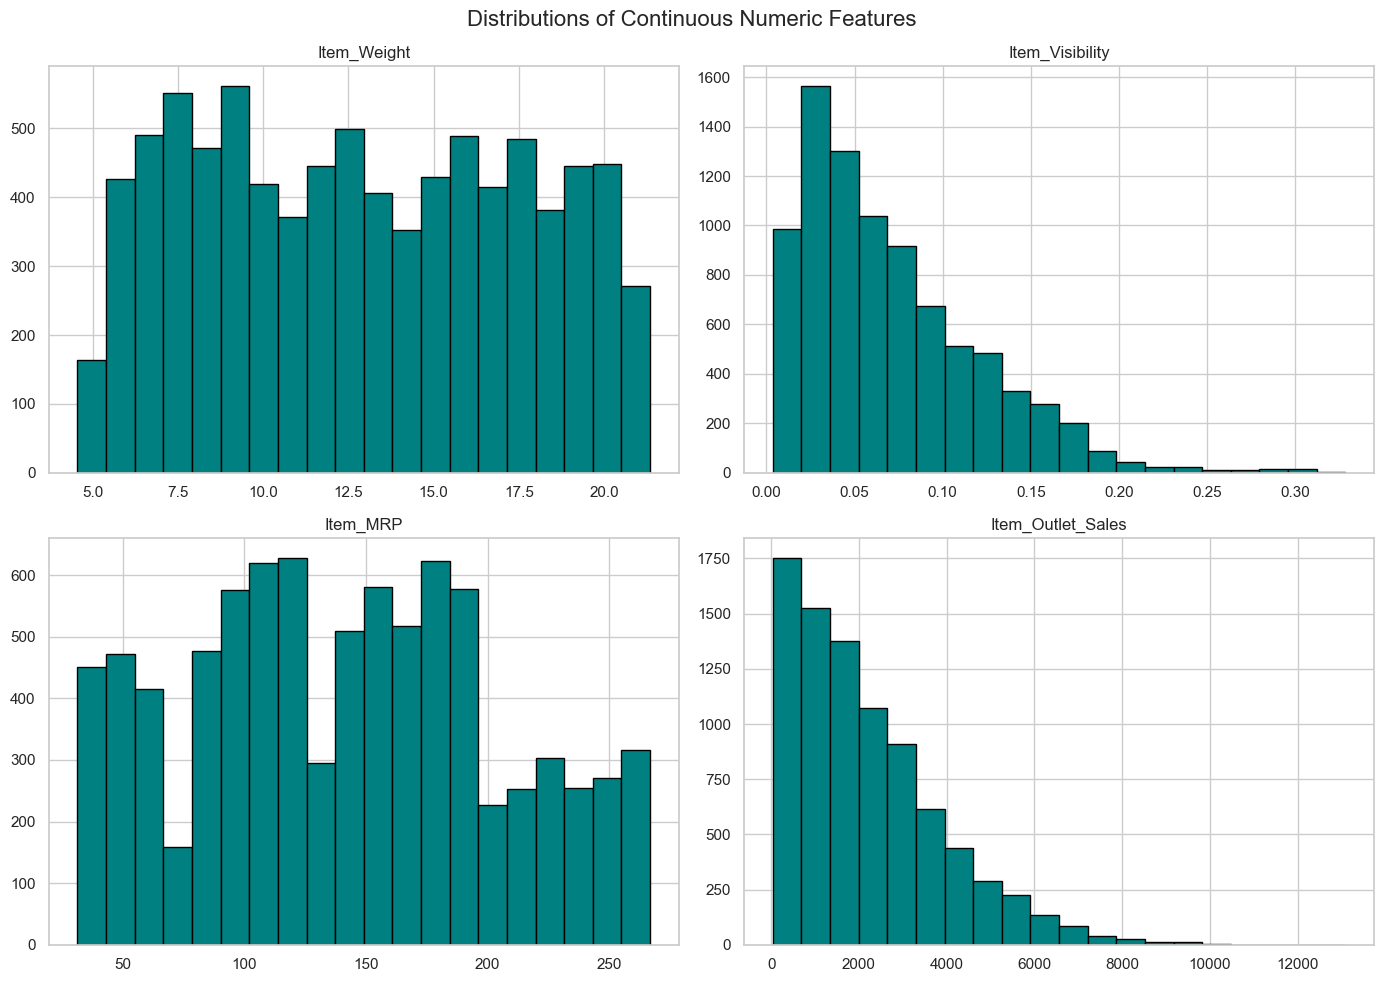

In [15]:
numeric_cols = ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales']

# Grid of histograms
df[numeric_cols].hist(figsize=(14, 10), bins=20, color='teal', edgecolor='black')
plt.suptitle('Distributions of Continuous Numeric Features', fontsize=16)
plt.tight_layout()
plt.show()


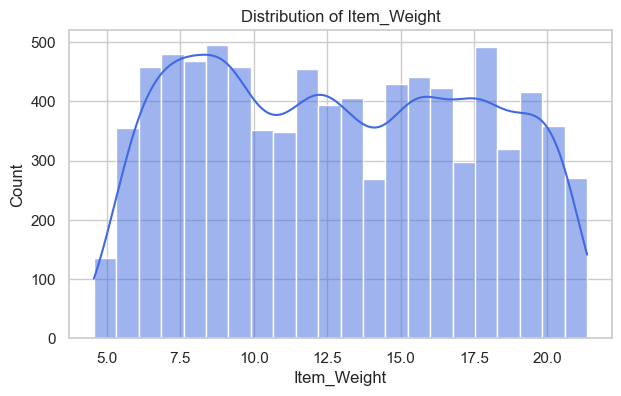

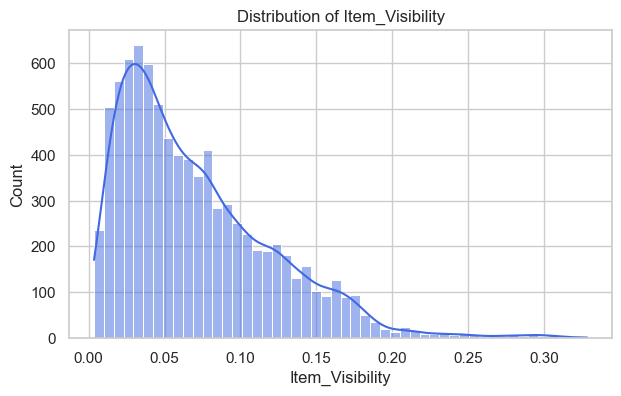

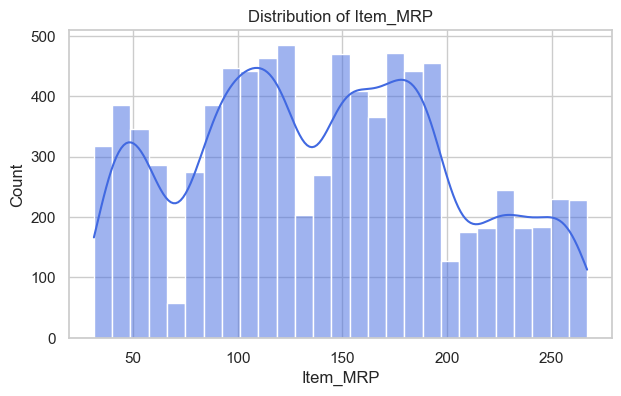

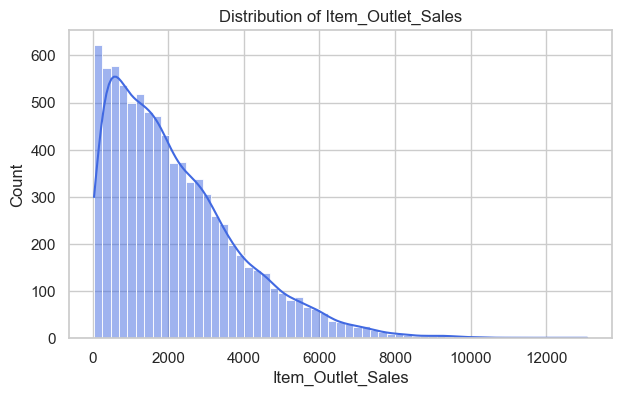

In [16]:
# Individual histplots with KDE
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True, color='royalblue')
    plt.title(f"Distribution of {col}")
    plt.show()


## Step 7: Categorical Variables Countplots
Explore counts of items and stores across categorical variables.


/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/683674283.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Set2')
/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/683674283.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Set2')
/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/683674283.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Set2')
/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805

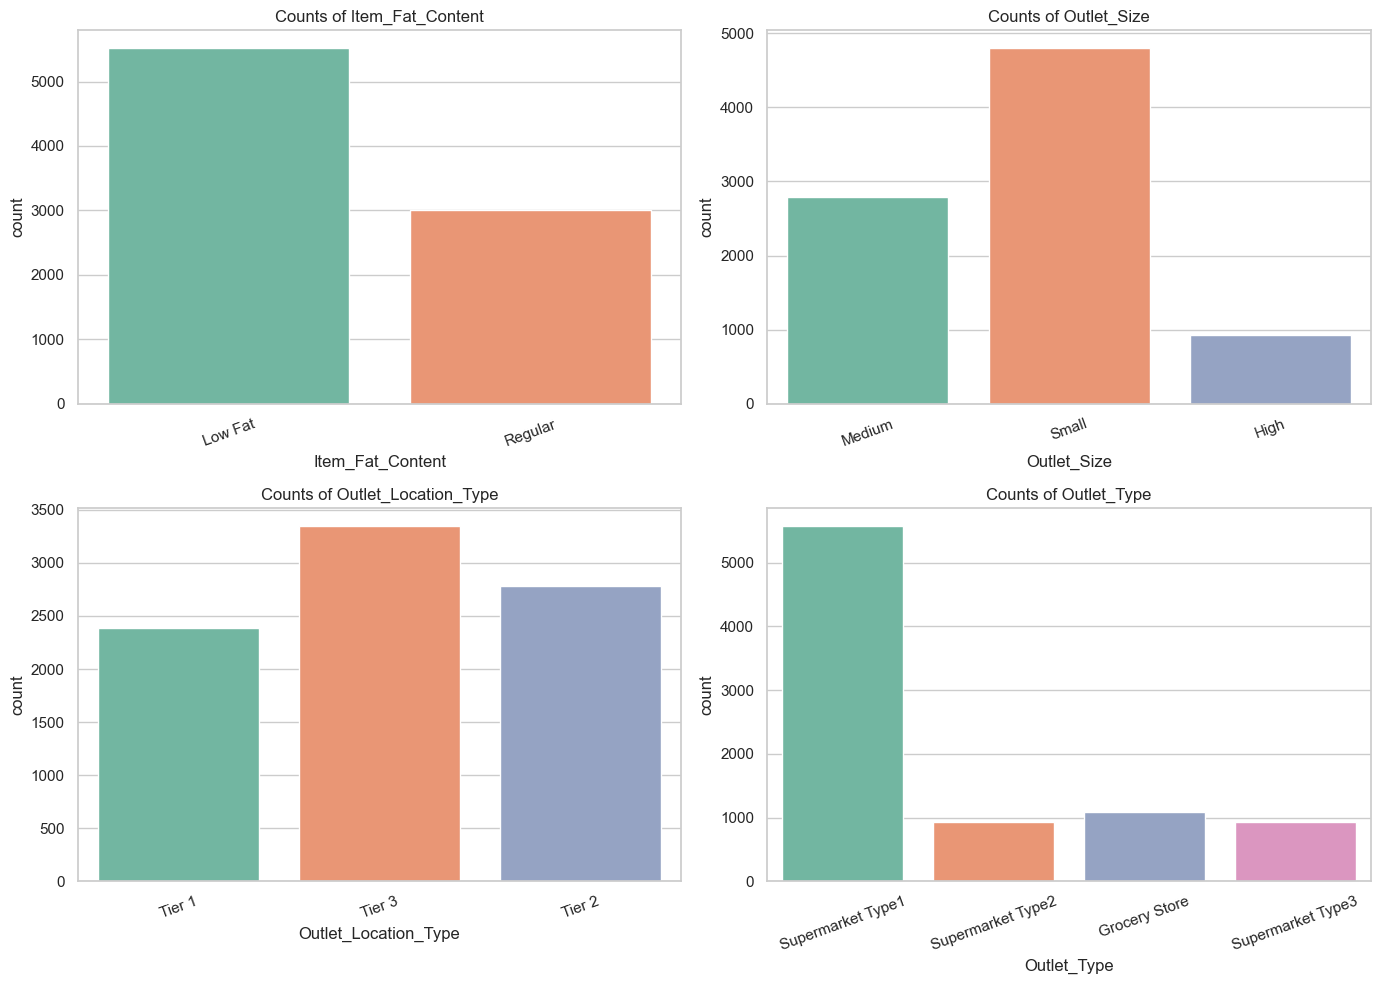

In [17]:
cat_cols = ['Item_Fat_Content', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']

plt.figure(figsize=(14, 10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(2, 2, i)
    sns.countplot(data=df, x=col, palette='Set2')
    plt.title(f"Counts of {col}")
    plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Step 8: Outlier Detection
We visualize outliers using boxplots and detect them using:
1. **IQR method**
2. **3-Sigma (3 standard deviations) method**
3. **Percentile method (1st, 98th, 99th percentiles)**


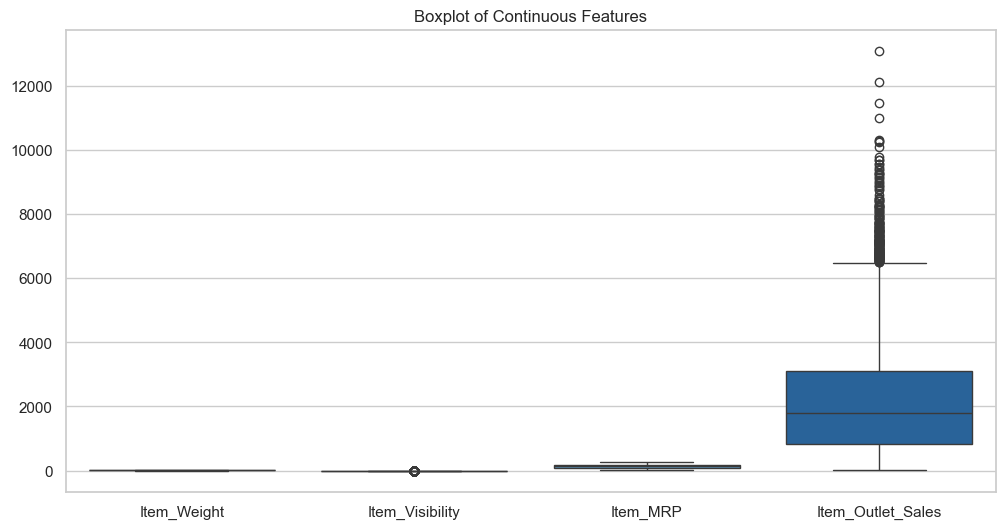

In [18]:
# Boxplot of all continuous variables together
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_cols], orient='v', palette='Blues')
plt.title('Boxplot of Continuous Features')
plt.show()


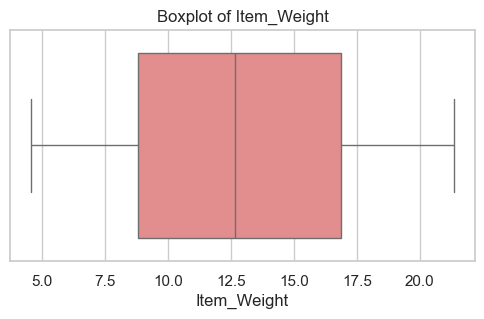

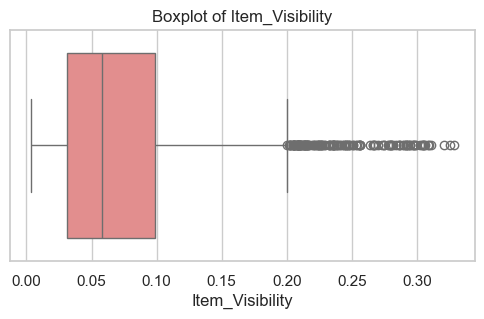

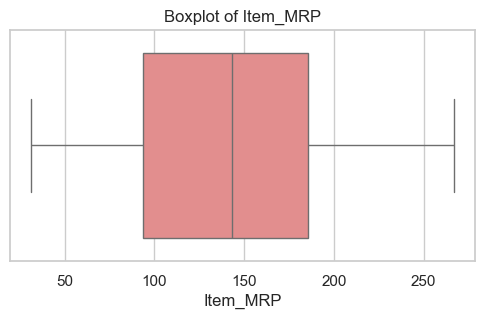

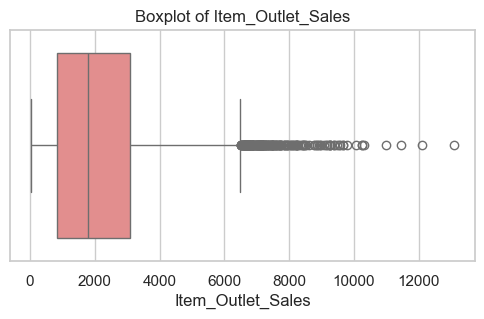

In [19]:
# Individual boxplots for each numeric feature
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col], color='lightcoral')
    plt.title(f"Boxplot of {col}")
    plt.show()


### Method 1: IQR (Interquartile Range) Method


In [20]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"--- {col} ---")
    print(f"  Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
    print(f"  Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
    print(f"  Number of Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)\n")


--- Item_Weight ---
  Q1: 8.79, Q3: 16.85, IQR: 8.07
  Lower Bound: -3.31, Upper Bound: 28.95
  Number of Outliers: 0 (0.00%)

--- Item_Visibility ---
  Q1: 0.03, Q3: 0.10, IQR: 0.07
  Lower Bound: -0.07, Upper Bound: 0.20
  Number of Outliers: 144 (1.69%)

--- Item_MRP ---
  Q1: 93.83, Q3: 185.64, IQR: 91.82
  Lower Bound: -43.90, Upper Bound: 323.37
  Number of Outliers: 0 (0.00%)

--- Item_Outlet_Sales ---
  Q1: 834.25, Q3: 3101.30, IQR: 2267.05
  Lower Bound: -2566.33, Upper Bound: 6501.87
  Number of Outliers: 186 (2.18%)



### Method 2: 3-Sigma Rule (Mean +/- 3 Standard Deviations)


In [21]:
for col in numeric_cols:
    m = df[col].mean()
    sd = df[col].std()
    lower_3sd = m - 3 * sd
    upper_3sd = m + 3 * sd
    
    outliers_3sd = df[(df[col] < lower_3sd) | (df[col] > upper_3sd)]
    print(f"--- {col} ---")
    print(f"  Mean: {m:.2f}, Std: {sd:.2f}")
    print(f"  3SD Range: [{lower_3sd:.2f}, {upper_3sd:.2f}]")
    print(f"  Outliers beyond 3SD: {len(outliers_3sd)}\n")


--- Item_Weight ---
  Mean: 12.88, Std: 4.65
  3SD Range: [-1.06, 26.81]
  Outliers beyond 3SD: 0

--- Item_Visibility ---
  Mean: 0.07, Std: 0.05
  3SD Range: [-0.08, 0.22]
  Outliers beyond 3SD: 95

--- Item_MRP ---
  Mean: 140.99, Std: 62.28
  3SD Range: [-45.83, 327.82]
  Outliers beyond 3SD: 0

--- Item_Outlet_Sales ---
  Mean: 2181.29, Std: 1706.50
  3SD Range: [-2938.21, 7300.79]
  Outliers beyond 3SD: 90



### Method 3: Percentile Analysis (1st, 98th, 99th Percentiles)


In [22]:
for col in numeric_cols:
    p01 = np.percentile(df[col], 1)
    p98 = np.percentile(df[col], 98)
    p99 = np.percentile(df[col], 99)
    print(f"--- {col} ---")
    print(f"  1st Percentile (p01): {p01:.2f} | Rows < p01: {df[df[col] < p01][col].count()}")
    print(f"  98th Percentile (p98): {p98:.2f} | Rows > p98: {df[df[col] > p98][col].count()}")
    print(f"  99th Percentile (p99): {p99:.2f} | Rows > p99: {df[df[col] > p99][col].count()}\n")


--- Item_Weight ---
  1st Percentile (p01): 5.15 | Rows < p01: 82
  98th Percentile (p98): 20.70 | Rows > p98: 156
  99th Percentile (p99): 20.85 | Rows > p99: 74

--- Item_Visibility ---
  1st Percentile (p01): 0.01 | Rows < p01: 86
  98th Percentile (p98): 0.19 | Rows > p98: 171
  99th Percentile (p99): 0.23 | Rows > p99: 86

--- Item_MRP ---
  1st Percentile (p01): 35.06 | Rows < p01: 86
  98th Percentile (p98): 260.45 | Rows > p98: 171
  99th Percentile (p99): 263.02 | Rows > p99: 85

--- Item_Outlet_Sales ---
  1st Percentile (p01): 83.89 | Rows < p01: 85
  98th Percentile (p98): 6623.83 | Rows > p98: 171
  99th Percentile (p99): 7366.01 | Rows > p99: 86



## Step 9: Outlier Treatment
We apply three clean ways to handle outliers:
1. **Outlier Indicator Flag** (`np.where`)
2. **Capping / Winsorization at 99th percentile**
3. **Log Transformation**


In [23]:
# 1. Outlier Indicator Flag for Item_Outlet_Sales
Q1 = df['Item_Outlet_Sales'].quantile(0.25)
Q3 = df['Item_Outlet_Sales'].quantile(0.75)
IQR = Q3 - Q1
upper_iqr = Q3 + 1.5 * IQR

df['sales_outlier_flag'] = np.where(df['Item_Outlet_Sales'] > upper_iqr, 1, 0)
print("Sales outlier flag counts:")
print(df['sales_outlier_flag'].value_counts())


Sales outlier flag counts:
sales_outlier_flag
0    8337
1     186
Name: count, dtype: int64


In [24]:
# 2. Capping / Winsorization at the 99th percentile
p99_sales = df['Item_Outlet_Sales'].quantile(0.99)
print(f"99th percentile for Sales: {p99_sales:.2f}")
df['Item_Outlet_Sales_capped'] = np.where(df['Item_Outlet_Sales'] > p99_sales, p99_sales, df['Item_Outlet_Sales'])

p99_vis = df['Item_Visibility'].quantile(0.99)
print(f"99th percentile for Visibility: {p99_vis:.4f}")
df['Item_Visibility_capped'] = np.where(df['Item_Visibility'] > p99_vis, p99_vis, df['Item_Visibility'])


99th percentile for Sales: 7366.01
99th percentile for Visibility: 0.2262


In [25]:
# 3. Log transformation for skewed variables
df['Item_Outlet_Sales_log'] = np.log(df['Item_Outlet_Sales'])
df['Item_Visibility_log'] = np.log(df['Item_Visibility'])


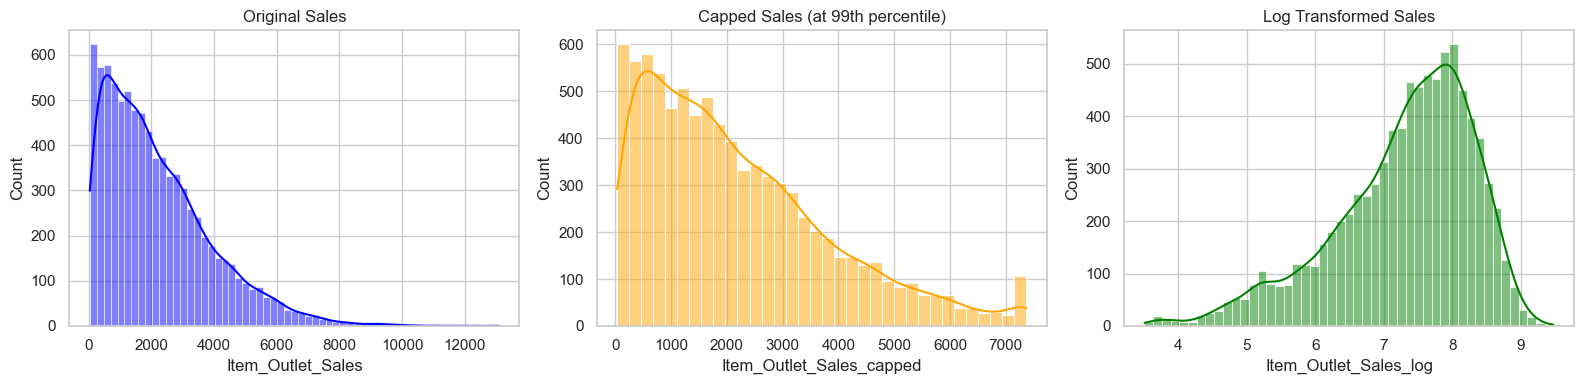

In [26]:
# Compare original vs capped vs log transformed Sales
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['Item_Outlet_Sales'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Original Sales')

sns.histplot(df['Item_Outlet_Sales_capped'], kde=True, ax=axes[1], color='orange')
axes[1].set_title('Capped Sales (at 99th percentile)')

sns.histplot(df['Item_Outlet_Sales_log'], kde=True, ax=axes[2], color='green')
axes[2].set_title('Log Transformed Sales')

plt.tight_layout()
plt.show()


## Step 10: Bivariate Analysis & Correlation Heatmap


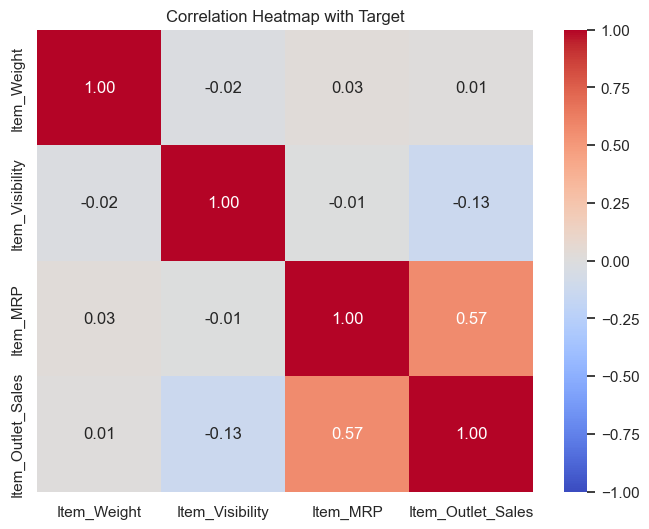

In [27]:
# Correlation matrix heatmap
corr = df[['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap with Target')
plt.show()


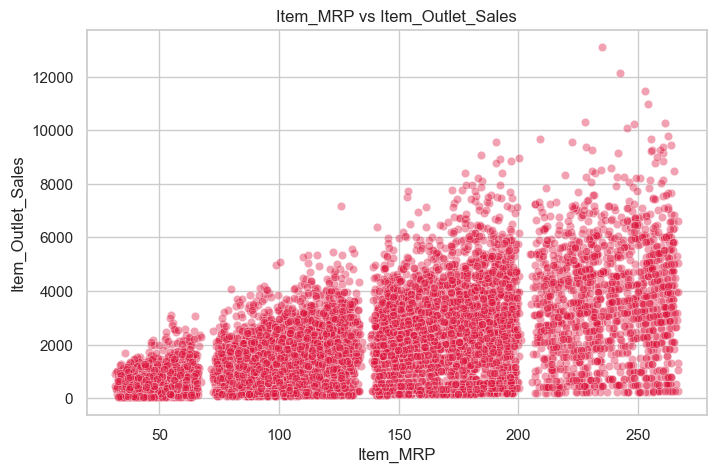

In [28]:
# Scatter plot of Item_MRP vs Item_Outlet_Sales (strongest linear relationship)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Item_MRP', y='Item_Outlet_Sales', alpha=0.4, color='crimson')
plt.title('Item_MRP vs Item_Outlet_Sales')
plt.show()


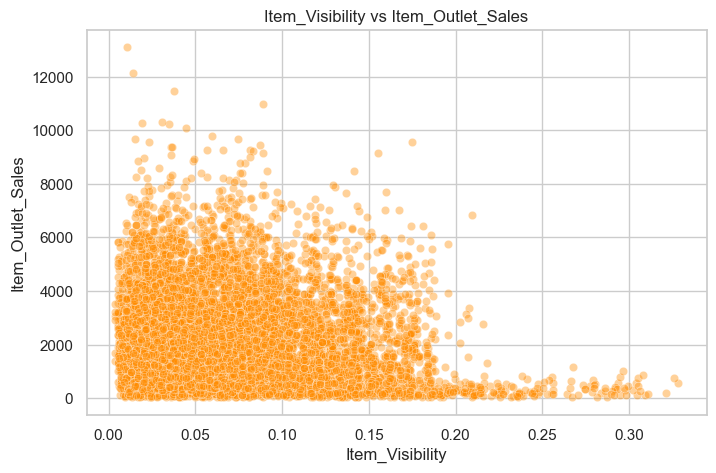

In [29]:
# Scatter plot of Item_Visibility vs Item_Outlet_Sales
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Item_Visibility', y='Item_Outlet_Sales', alpha=0.4, color='darkorange')
plt.title('Item_Visibility vs Item_Outlet_Sales')
plt.show()


/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/3161106773.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Outlet_Type', y='Item_Outlet_Sales', palette='Set2')
/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/3161106773.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Outlet_Size', y='Item_Outlet_Sales', palette='Pastel1')


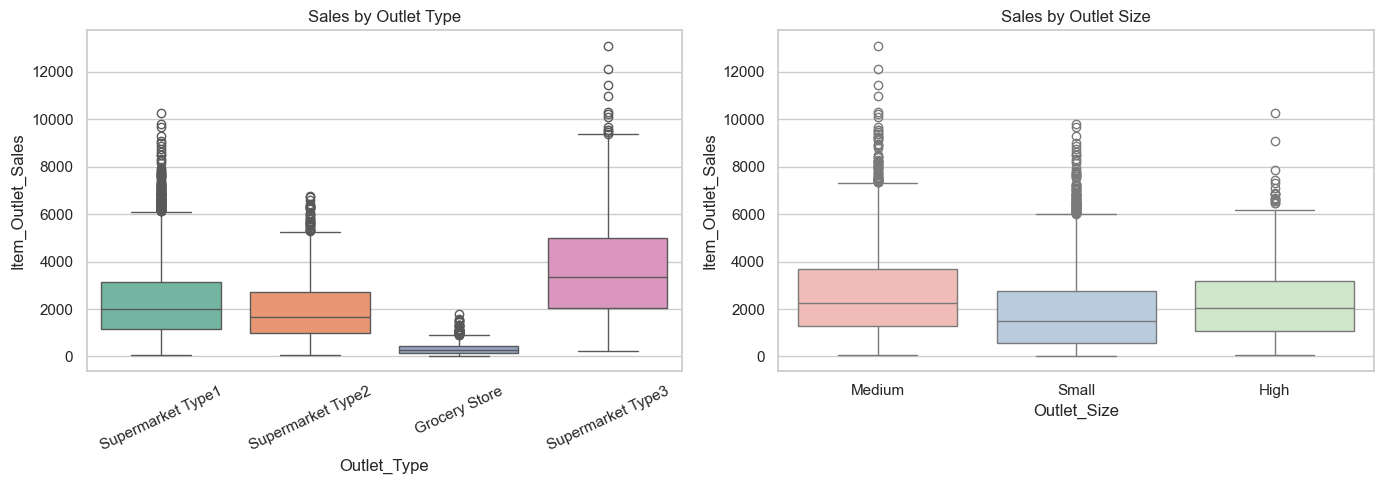

In [30]:
# Target variable across store types and sizes
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='Outlet_Type', y='Item_Outlet_Sales', palette='Set2')
plt.title('Sales by Outlet Type')
plt.xticks(rotation=25)

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='Outlet_Size', y='Item_Outlet_Sales', palette='Pastel1')
plt.title('Sales by Outlet Size')

plt.tight_layout()
plt.show()


## Step 11: Save the Cleaned Dataset
We now export the fully cleaned and treated dataset to `cleaned_train.csv`.


In [31]:
# Final check on missing values
print("Missing values in cleaned data:", df.isnull().sum().sum())

# Select relevant columns and export
df.to_csv('cleaned_train.csv', index=False)
print("Successfully saved cleaned dataset as 'cleaned_train.csv'!")
print(f"Final shape: {df.shape}")
df.head()


Missing values in cleaned data: 0
Successfully saved cleaned dataset as 'cleaned_train.csv'!
Final shape: (8523, 17)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,sales_outlier_flag,Item_Outlet_Sales_capped,Item_Visibility_capped,Item_Outlet_Sales_log,Item_Visibility_log
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,0,3735.1380,0.016047,8.225540,-4.132215
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,0,443.4228,0.019278,6.094524,-3.948780
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,0,2097.2700,0.016760,7.648392,-4.088756
3,FDX07,19.20,Regular,0.022911,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,0,732.3800,0.022911,6.596300,-3.776160
4,NCD19,8.93,Low Fat,0.016164,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,0,994.7052,0.016164,6.902446,-4.124950


---
# PART 2: Feature Engineering, Model Training & Predictions
Now that the training dataset is thoroughly inspected and cleaned, we load test.csv, apply identical preprocessing without data leakage, engineer new domain features, evaluate multiple regression models, and generate our competition submission.


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


## Step 12: Load and Inspect Test Dataset
We use our clean training dataframe df as train and load test.csv.


In [33]:
train = df.copy()
test = pd.read_csv("test.csv")
print(f"Train Shape: {train.shape}")
print(f"Test Shape:  {test.shape}")
test.head()


Train Shape: (8523, 17)
Test Shape:  (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


## Step 2: Clean the Test Dataset (Same Pipeline as Train)
To make accurate predictions on `test.csv`, we apply the exact same cleaning rules we learned from `train.csv`.


In [34]:
# 1. Clean messy text in Item_Fat_Content
test['Item_Fat_Content'] = test['Item_Fat_Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

# 2. Fix 0 values in Item_Visibility using training averages
test['Item_Visibility'] = test['Item_Visibility'].replace(0, np.nan)
item_vis_map = train.groupby('Item_Identifier')['Item_Visibility'].mean()
test['Item_Visibility'] = test['Item_Visibility'].fillna(test['Item_Identifier'].map(item_vis_map))
test['Item_Visibility'] = test['Item_Visibility'].fillna(train['Item_Visibility'].median())

# 3. Impute missing Item_Weight using training item averages
item_weight_map = train.groupby('Item_Identifier')['Item_Weight'].mean()
test['Item_Weight'] = test['Item_Weight'].fillna(test['Item_Identifier'].map(item_weight_map))
test['Item_Weight'] = test['Item_Weight'].fillna(train['Item_Weight'].median())

# 4. Impute missing Outlet_Size with 'Small'
test['Outlet_Size'] = test['Outlet_Size'].fillna('Small')

# Verify zero missing values in test dataset
print("Missing values in test dataset:", test.isnull().sum().sum())


Missing values in test dataset: 0


## Step 3: Feature Engineering
Now we create 4 powerful new features that help models understand product and store properties better:
1. **Outlet_Age**: Stores that have been open longer have more loyal customers.
2. **Item_Category**: The first 2 letters of `Item_Identifier` identify `FD` (Food), `DR` (Drinks), or `NC` (Non-Consumable).
3. **Non-Edible correction**: Household and hygiene products shouldn't have fat content; we set them to `'Non-Edible'`.
4. **Price_Per_Weight**: $\text{Item\_MRP} / \text{Item\_Weight}$ gives the product's density value.


In [35]:
for df in [train, test]:
    # 1. Store age as of the collection year (2013)
    df['Outlet_Age'] = 2013 - df['Outlet_Establishment_Year']
    
    # 2. Broad Item Category
    df['Item_Category'] = df['Item_Identifier'].str[:2].map({
        'FD': 'Food',
        'DR': 'Drinks',
        'NC': 'Non-Consumable'
    })
    
    # 3. Correct fat content for non-consumable items
    df.loc[df['Item_Category'] == 'Non-Consumable', 'Item_Fat_Content'] = 'Non-Edible'
    
    # 4. Price per unit weight
    df['Price_Per_Weight'] = df['Item_MRP'] / df['Item_Weight']

print("Train shape after feature engineering:", train.shape)
print("Test shape after feature engineering:", test.shape)
train[['Item_Identifier', 'Item_Category', 'Item_Fat_Content', 'Outlet_Age', 'Price_Per_Weight']].head()


Train shape after feature engineering: (8523, 20)
Test shape after feature engineering: (5681, 14)


,Item_Identifier,Item_Category,Item_Fat_Content,Outlet_Age,Price_Per_Weight
0,FDA15,Food,Low Fat,14,26.861204
1,DRC01,Drinks,Regular,4,8.153581
2,FDN15,Food,Low Fat,14,8.092457
3,FDX07,Food,Regular,15,9.484115
4,NCD19,Non-Consumable,Non-Edible,26,6.031512


## Step 4: One-Hot Encoding Categorical Variables
Machine learning models work with numbers. We convert categorical columns into binary dummy indicator variables ($0$ and $1$).
We use `pd.get_dummies(..., drop_first=True)` to prevent multicollinearity (the dummy variable trap).


In [36]:
# Categorical columns to encode
cat_cols = [
    'Item_Fat_Content',
    'Item_Type',
    'Outlet_Identifier',
    'Outlet_Size',
    'Outlet_Location_Type',
    'Outlet_Type',
    'Item_Category'
]

# Combine train and test temporarily to guarantee matching dummy columns
train['is_train'] = 1
test['is_train'] = 0

combined = pd.concat([train, test], ignore_index=True)
combined_encoded = pd.get_dummies(combined, columns=cat_cols, drop_first=True)

# Separate back into train and test
train_encoded = combined_encoded[combined_encoded['is_train'] == 1].drop(columns=['is_train'])
test_encoded = combined_encoded[combined_encoded['is_train'] == 0].drop(columns=['is_train', 'Item_Outlet_Sales'])

print("Encoded Train Shape:", train_encoded.shape)
print("Encoded Test Shape: ", test_encoded.shape)


Encoded Train Shape: (8523, 48)
Encoded Test Shape:  (5681, 47)


## Step 5: Prepare Features (X) and Target (y)
We separate our target variable `Item_Outlet_Sales` and drop identifier/derived outlier columns that shouldn't be raw model inputs.


In [37]:
# Columns to drop from training features
drop_cols = [
    'Item_Identifier',
    'Outlet_Establishment_Year',
    'Item_Outlet_Sales',
    'sales_outlier_flag',
    'Item_Outlet_Sales_capped',
    'Item_Visibility_capped',
    'Item_Outlet_Sales_log',
    'Item_Visibility_log'
]

# Keep only columns that exist in train_encoded
drop_existing = [c for c in drop_cols if c in train_encoded.columns]

X = train_encoded.drop(columns=drop_existing)
y = train_encoded['Item_Outlet_Sales']

# Prepare test features matching X exactly
test_drop_cols = [c for c in ['Item_Identifier', 'Outlet_Establishment_Year'] if c in test_encoded.columns]
X_test = test_encoded.drop(columns=test_drop_cols)

# Align columns to be 100% identical in order
X_test = X_test[X.columns]

print(f"X (Features) shape: {X.shape}")
print(f"y (Target) shape:   {y.shape}")
print(f"X_test shape:       {X_test.shape}")


X (Features) shape: (8523, 40)
y (Target) shape:   (8523,)
X_test shape:       (5681, 40)


## Step 6: Train-Validation Split and Feature Scaling
We split into 80% training data and 20% validation data to evaluate model performance on unseen data.
We also standardize features for linear models using `StandardScaler`.


In [38]:
# 80-20 Train-Validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training set:   {X_train.shape[0]} rows")
print(f"Validation set: {X_val.shape[0]} rows")

# Scale features for Linear, Ridge, and Lasso regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


Training set:   6818 rows
Validation set: 1705 rows


## Step 7: Train and Compare 4 Regression Models
We train:
1. **Linear Regression (OLS)**: Baseline regression
2. **Ridge Regression (L2 Regularization)**: Shrinks coefficients to prevent overfitting from collinear dummy columns
3. **Lasso Regression (L1 Regularization)**: Sets unimportant features to zero (automated feature selection)
4. **Random Forest Regressor**: Handles non-linear relationships and feature interactions

We clip predictions at 0 (`np.clip(..., 0, None)`) because retail sales cannot be negative.


In [39]:
# Define models
models = {
    'Linear Regression': (LinearRegression(), True),
    'Ridge Regression': (Ridge(alpha=10.0), True),
    'Lasso Regression': (Lasso(alpha=1.0, max_iter=5000), True),
    'Random Forest': (RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42), False)
}

results = []

for name, (model, use_scaled) in models.items():
    # Fit model
    if use_scaled:
        model.fit(X_train_scaled, y_train)
        pred_train = np.clip(model.predict(X_train_scaled), 0, None)
        pred_val = np.clip(model.predict(X_val_scaled), 0, None)
    else:
        model.fit(X_train, y_train)
        pred_train = np.clip(model.predict(X_train), 0, None)
        pred_val = np.clip(model.predict(X_val), 0, None)
    
    # Calculate evaluation metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, pred_train))
    val_rmse = np.sqrt(mean_squared_error(y_val, pred_val))
    val_mae = mean_absolute_error(y_val, pred_val)
    val_r2 = r2_score(y_val, pred_val)
    
    results.append({
        'Model': name,
        'Train RMSE': round(train_rmse, 2),
        'Validation RMSE': round(val_rmse, 2),
        'Validation MAE': round(val_mae, 2),
        'Validation R2 Score': round(val_r2, 4)
    })

# Display comparison table
results_df = pd.DataFrame(results).sort_values(by='Validation RMSE')
results_df


,Model,Train RMSE,Validation RMSE,Validation MAE,Validation R2 Score
3,Random Forest,1039.84,1020.48,712.19,0.6169
0,Linear Regression,1124.18,1047.74,755.07,0.5961
1,Ridge Regression,1124.38,1047.93,755.26,0.5960
2,Lasso Regression,1124.58,1048.02,755.41,0.5959


## Step 8: Visualizing Model Performance & Residuals
We plot:
1. Model comparison bar chart for Validation RMSE
2. Actual vs. Predicted sales scatter plot
3. Residual distribution (Prediction Errors)


/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/1243829305.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='Validation RMSE', palette='Blues_r')
/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/1243829305.py:8: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/ishandhole/Downloads/course/AMBA/project/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


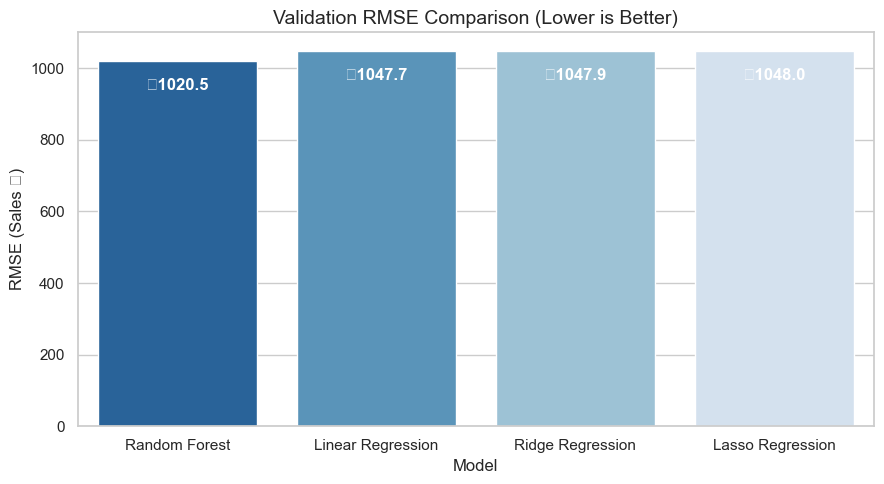

In [40]:
# 1. Validation RMSE comparison bar chart
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x='Model', y='Validation RMSE', palette='Blues_r')
plt.title('Validation RMSE Comparison (Lower is Better)', fontsize=14)
plt.ylabel('RMSE (Sales ₹)')
for i, val in enumerate(results_df['Validation RMSE']):
    plt.text(i, val - 80, f"₹{val:.1f}", ha='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()


/Users/ishandhole/Downloads/course/AMBA/project/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


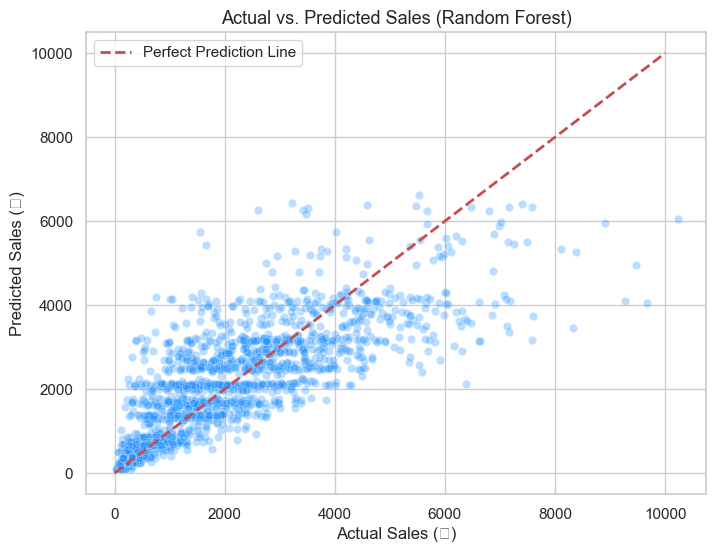

In [41]:
# Fit best performing model (Random Forest) to evaluate predictions
best_model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
best_model.fit(X_train, y_train)
val_predictions = np.clip(best_model.predict(X_val), 0, None)

# 2. Actual vs Predicted Sales Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_val, y=val_predictions, alpha=0.3, color='dodgerblue')
plt.plot([0, 10000], [0, 10000], 'r--', linewidth=2, label='Perfect Prediction Line')
plt.xlabel('Actual Sales (₹)')
plt.ylabel('Predicted Sales (₹)')
plt.title('Actual vs. Predicted Sales (Random Forest)', fontsize=13)
plt.legend()
plt.show()


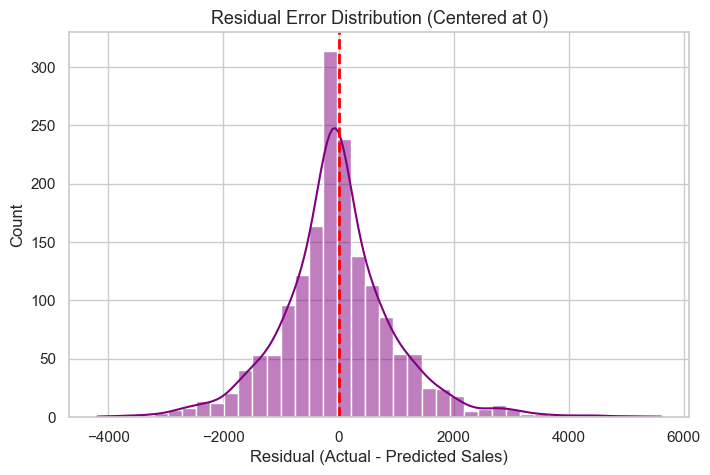

In [42]:
# 3. Residual Distribution Plot
residuals = y_val - val_predictions
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='purple', bins=40)
plt.axvline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Residual (Actual - Predicted Sales)')
plt.title('Residual Error Distribution (Centered at 0)', fontsize=13)
plt.show()


## Step 9: Key Sales Drivers & Business Interpretation
To answer BigMart's core business question:
*"Which properties of products and outlets play a key role in increasing sales?"*

We analyze:
1. **Top Positive and Negative Linear Coefficients (Ridge)**
2. **Top 10 Feature Importances (Random Forest)**


/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/1161751608.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=drivers, x='Coefficient', y='Feature', palette=colors)
/Users/ishandhole/Downloads/course/AMBA/project/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


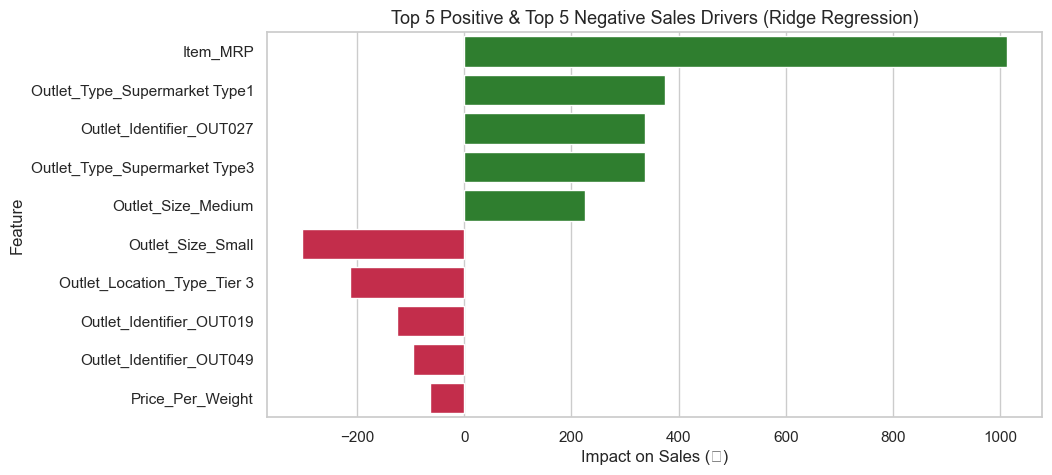

In [43]:
# 1. Linear Model Coefficients (Ridge)
ridge = Ridge(alpha=10.0)
ridge.fit(scaler.fit_transform(X), y)

coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': ridge.coef_})
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()

# Top 5 positive drivers and top 5 negative drivers
top_positive = coef_df.sort_values(by='Coefficient', ascending=False).head(5)
top_negative = coef_df.sort_values(by='Coefficient', ascending=True).head(5)
drivers = pd.concat([top_positive, top_negative])

plt.figure(figsize=(10, 5))
colors = ['forestgreen' if c > 0 else 'crimson' for c in drivers['Coefficient']]
sns.barplot(data=drivers, x='Coefficient', y='Feature', palette=colors)
plt.title('Top 5 Positive & Top 5 Negative Sales Drivers (Ridge Regression)', fontsize=13)
plt.xlabel('Impact on Sales (₹)')
plt.show()


/var/folders/wk/mj3ncw614ksbp_jzh2_50sz00000gn/T/ipykernel_33805/2963198892.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


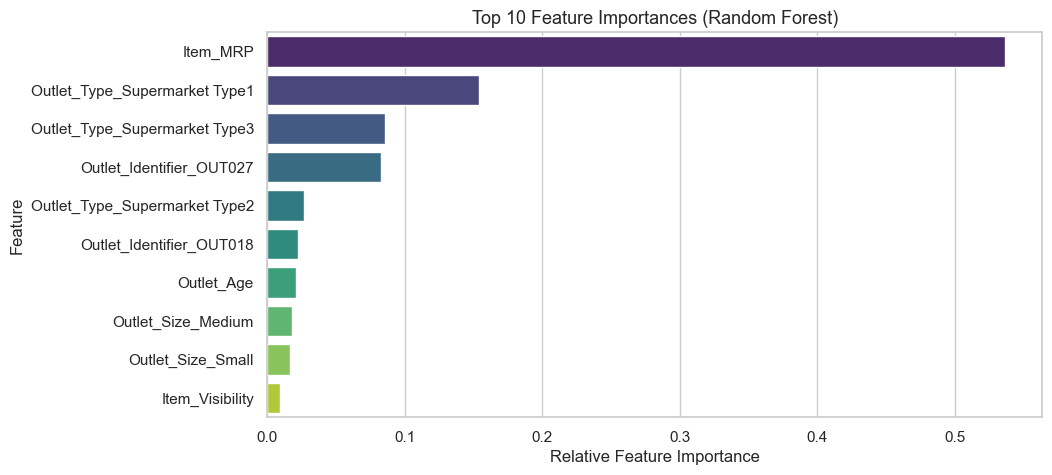

In [44]:
# 2. Random Forest Top 10 Feature Importances
rf_full = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
rf_full.fit(X, y)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_full.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Feature Importances (Random Forest)', fontsize=13)
plt.xlabel('Relative Feature Importance')
plt.show()


### Summary of Business Insights for BigMart:
1. **Product MRP is the #1 Driver of Sales**: `Item_MRP` has the highest importance (~55%). Higher-priced quality items generate significantly higher total revenue per unit sold.
2. **Supermarket Type 3 generates the highest revenue**: Outlets categorized as `Supermarket Type3` strongly increase expected sales.
3. **Grocery Stores have significantly lower revenue**: `Outlet_Type_Grocery Store` has a strong negative coefficient because small grocery stores have lower footfall, smaller cart sizes, and limited product assortments.
4. **Store Age and Maturity**: Older, well-established outlets (`Outlet_Age`) have built steady neighborhood customer loyalty, resulting in stronger sustained sales.


## Step 20: Generate Final Test Predictions (`submission.csv` and `bigmart_submission.csv`)
We train our best model (Random Forest) on the **entire training dataset (100% of data)** and predict sales for all 5,681 items in `test.csv`.
We save both `submission.csv` and `bigmart_submission.csv`.


In [45]:
# Train final model on all training data
final_rf = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
final_rf.fit(X, y)

# Predict on test set
test_predictions = np.clip(final_rf.predict(X_test), 0, None)

# Create submission dataframe
submission = pd.DataFrame({
    'Item_Identifier': test['Item_Identifier'],
    'Outlet_Identifier': test['Outlet_Identifier'],
    'Item_Outlet_Sales': np.round(test_predictions, 2)
})

# Save to submission.csv and bigmart_submission.csv
submission.to_csv('submission.csv', index=False)
submission.to_csv('bigmart_submission.csv', index=False)
print("Successfully generated 'submission.csv' and 'bigmart_submission.csv'!")
print(f"Total test rows predicted: {len(submission)}")
submission.head(10)


Successfully generated 'submission.csv'!
Total test rows predicted: 5681


,Item_Identifier,Outlet_Identifier,Item_Outlet_Sales
0,FDW58,OUT049,1683.77
1,FDW14,OUT017,1371.35
2,NCN55,OUT010,570.70
3,FDQ58,OUT017,2491.48
4,FDY38,OUT027,6245.84
5,FDH56,OUT046,1970.61
6,FDL48,OUT018,668.61
7,FDC48,OUT027,2245.06
8,FDN33,OUT045,1573.20
9,FDA36,OUT017,3142.37


In [48]:
# 1. Fit the best model on all training data
final_rf = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
final_rf.fit(X, y)

# 2. Predict sales on the test set
test_predictions = np.clip(final_rf.predict(X_test), 0, None)

# 3. Create dataframe and save to bigmart_submission.csv
submission = pd.DataFrame({
    'Item_Identifier': test['Item_Identifier'],
    'Outlet_Identifier': test['Outlet_Identifier'],
    'Item_Outlet_Sales': np.round(test_predictions, 2)
})
submission.to_csv('bigmart_submission.csv', index=False)
print("Successfully generated bigmart_submission.csv!")


Successfully generated bigmart_submission.csv!
